Simulation finished. Figures saved: wind_profile.png, rotor_speed.png, torques.png, powers.png


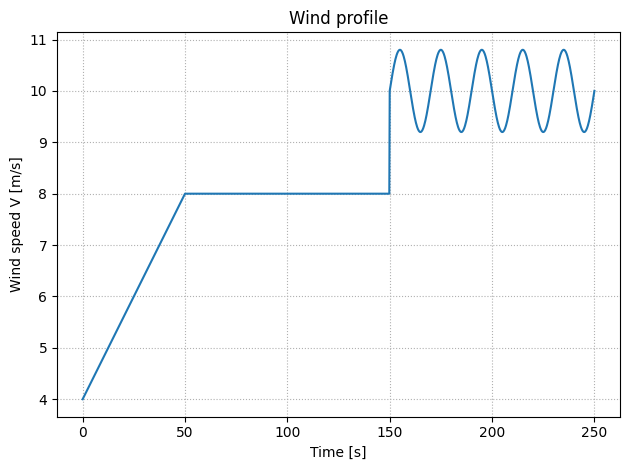

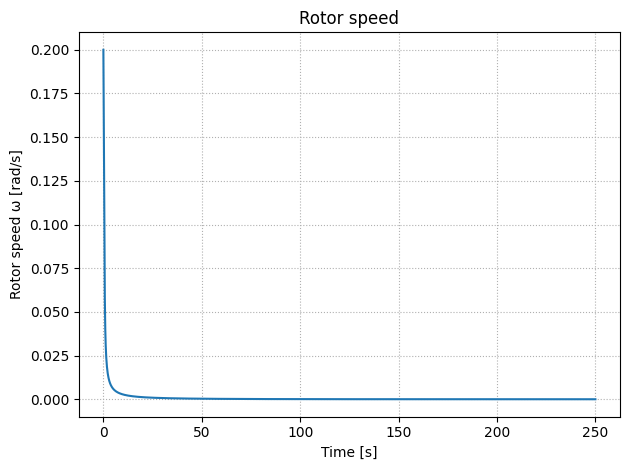

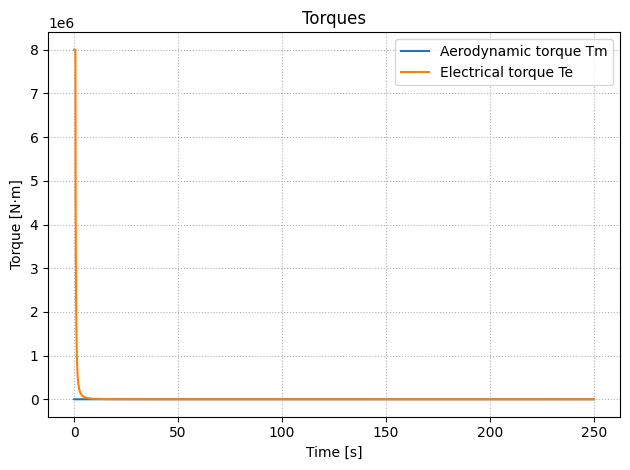

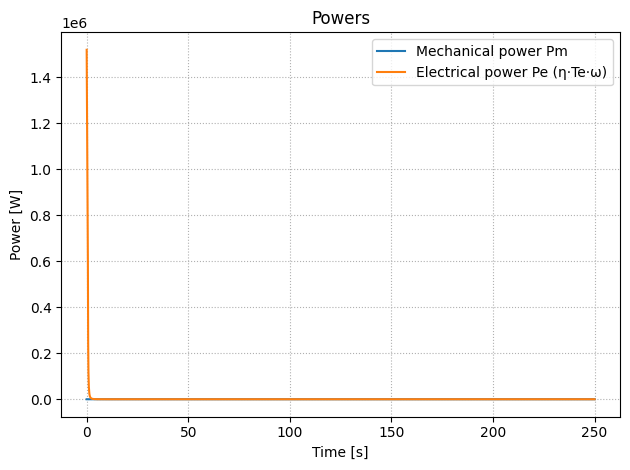

In [2]:
# Simple wind turbine (1-state) simulation using solve_ivp
# Notes:
# - One mechanical state: rotor speed omega [rad/s].
# - Aerodynamics via Cp(lambda) using a smooth parabola around the optimum.
# - Electrical torque uses a simple MPPT law: Te = Kopt * omega**2.
# - Includes basic cut-in / cut-out logic and numerical protections.

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ----------------------------
# Parameters (edit as needed)
# ----------------------------
rho = 1.225          # air density [kg/m^3]
R = 50.0             # rotor radius [m] ~ 100 m diameter utility-scale
A = np.pi * R**2     # swept area [m^2]
J = 4.0e7            # equivalent inertia [kg*m^2] (order-of-magnitude)
B = 1.0e6            # viscous friction [N*m*s]
eta = 0.95           # overall efficiency for Pelec = eta*Te*omega (not used in dynamics)

# Cp(lambda) parabola parameters
Cp_max = 0.45
lambda_opt = 8.0
k_shape = 0.04       # curvature around lambda_opt

# MPPT torque law Te = Kopt * omega^2
Kopt = 0.5 * rho * A * (R**5) * (Cp_max / (lambda_opt**3))

# Operational limits
V_in = 3.0           # cut-in wind speed [m/s]
V_out = 25.0         # cut-out wind speed [m/s]
omega_max = 2.5      # mechanical speed limit [rad/s]
Te_max = 8.0e6       # max electromagnetic torque [N*m]
epsilon = 1.0e-3     # small number to avoid division by zero

# ----------------------------
# Helper functions
# ----------------------------
def cp_of_lambda(lmbd: float) -> float:
    """Parabolic Cp around lambda_opt with floor at 0."""
    value = Cp_max * (1.0 - k_shape * (lmbd - lambda_opt)**2)
    if value < 0.0:
        value = 0.0
    if value > Cp_max:
        value = Cp_max
    return value

def wind_profile(t: float) -> float:
    """Simple wind profile: ramp + step + gusts (replace as needed)."""
    # 0–50 s: ramp from 4 to 8 m/s; 50–150 s: 8 m/s; 150–250 s: 10 m/s with small gusts
    if t < 50.0:
        v = 4.0 + (8.0 - 4.0) * (t / 50.0)
    elif t < 150.0:
        v = 8.0
    else:
        v = 10.0 + 0.8 * np.sin(2.0 * np.pi * (t - 150.0) / 20.0)
    return v

def electrical_torque_cmd(omega: float, V: float) -> float:
    """MPPT torque with basic operational limits."""
    # Cut-in and cut-out handling
    if V < V_in or V > V_out:
        return 0.0
    # MPPT law
    Te = Kopt * (omega**2)
    # Speed and torque caps
    if omega > omega_max:
        Te = 0.0  # feathering / braking effect to respect omega_max (simplified)
    if Te > Te_max:
        Te = Te_max
    if Te < 0.0:
        Te = 0.0
    return Te

# ----------------------------
# ODE: J * domega = Tm - Te - B*omega
# ----------------------------
def turbine_ode(t: float, x: np.ndarray) -> np.ndarray:
    omega = x[0]
    V = wind_profile(t)

    # Aerodynamic torque Tm = 0.5*rho*A*V^3 * Cp(lambda) / omega
    if V <= 0.0:
        V = 0.0
    if omega < epsilon:
        omega_eff = epsilon
    else:
        omega_eff = omega
    if V < epsilon:
        lambda_ts = 0.0
    else:
        lambda_ts = (R * omega_eff) / V

    Cp = cp_of_lambda(lambda_ts)
    Pm = 0.5 * rho * A * (V**3) * Cp
    Tm = Pm / omega_eff

    Te = electrical_torque_cmd(omega, V)

    domega = (Tm - Te - B * omega) / J
    return np.array([domega])

# ----------------------------
# Simulation
# ----------------------------
t0 = 0.0
tf = 250.0
x0 = np.array([0.2])   # small initial speed [rad/s]
sol = solve_ivp(
    fun=turbine_ode,
    t_span=(t0, tf),
    y0=x0,
    method="RK45",
    max_step=0.2,
    rtol=1e-6,
    atol=1e-9,
    dense_output=False
)

# ----------------------------
# Post-processing
# ----------------------------
t = sol.t
omega = sol.y[0]
V = np.array([wind_profile(tt) for tt in t])

# Recompute torques and powers for plotting
Tm_list = []
Te_list = []
Pm_list = []
Pe_list = []
for i in range(len(t)):
    Vi = V[i]
    omegai = omega[i]
    if omegai < epsilon:
        omegai_eff = epsilon
    else:
        omegai_eff = omegai
    if Vi < epsilon:
        lambda_i = 0.0
    else:
        lambda_i = (R * omegai_eff) / Vi
    Cp_i = cp_of_lambda(lambda_i)
    Pm_i = 0.5 * rho * A * (Vi**3) * Cp_i
    Tm_i = Pm_i / omegai_eff
    Te_i = electrical_torque_cmd(omegai, Vi)
    Pe_i = eta * Te_i * omegai
    Tm_list.append(Tm_i)
    Te_list.append(Te_i)
    Pm_list.append(Pm_i)
    Pe_list.append(Pe_i)

Tm = np.array(Tm_list)
Te = np.array(Te_list)
Pm = np.array(Pm_list)
Pe = np.array(Pe_list)

# ----------------------------
# Plots (saved at 300 dpi)
# ----------------------------
plt.figure()
plt.plot(t, V)
plt.xlabel("Time [s]")
plt.ylabel("Wind speed V [m/s]")
plt.title("Wind profile")
plt.grid(True, which="both", ls=":")
plt.tight_layout()
plt.savefig("wind_profile.png", dpi=300)

plt.figure()
plt.plot(t, omega)
plt.xlabel("Time [s]")
plt.ylabel("Rotor speed ω [rad/s]")
plt.title("Rotor speed")
plt.grid(True, which="both", ls=":")
plt.tight_layout()
plt.savefig("rotor_speed.png", dpi=300)

plt.figure()
plt.plot(t, Tm, label="Aerodynamic torque Tm")
plt.plot(t, Te, label="Electrical torque Te")
plt.xlabel("Time [s]")
plt.ylabel("Torque [N·m]")
plt.title("Torques")
plt.legend()
plt.grid(True, which="both", ls=":")
plt.tight_layout()
plt.savefig("torques.png", dpi=300)

plt.figure()
plt.plot(t, Pm, label="Mechanical power Pm")
plt.plot(t, Pe, label="Electrical power Pe (η·Te·ω)")
plt.xlabel("Time [s]")
plt.ylabel("Power [W]")
plt.title("Powers")
plt.legend()
plt.grid(True, which="both", ls=":")
plt.tight_layout()
plt.savefig("powers.png", dpi=300)

print("Simulation finished. Figures saved: wind_profile.png, rotor_speed.png, torques.png, powers.png")
